In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
from matplotlib import cm
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json
from subprocess import Popen, PIPE
import requests

today = date.today()

**Number of non-zero factors per regions**

In [4]:
ss_datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/sfc'
full_datadir = '/home/ctrader/region_similarity/data/rank_based/hilbert/sfc'

In [5]:
f = h5py.File(os.path.join(full_datadir, 'hilbert_regions_order_4_CT20230630.dhs.sfc.ranks.hdf5'), 'r')
dhs_factors = np.char.decode(f['factors'][:])
dhs_colors = np.char.decode(f['colors'][:])
f.close()

f = h5py.File(os.path.join(full_datadir, 'hilbert_regions_order_7_CT20230630.cs.sfc.ranks.hdf5'), 'r')
cs_factors = np.char.decode(f['factors'][:])
cs_colors = np.char.decode(f['colors'][:])
f.close()

factors = np.append(dhs_factors, cs_factors)
colors = np.append(dhs_colors, cs_colors)
colors[-1] = '#d9d9d9'

Text(0.5, 0.93, 'Factors with Non-zero SFC for All Regions at Each Order')

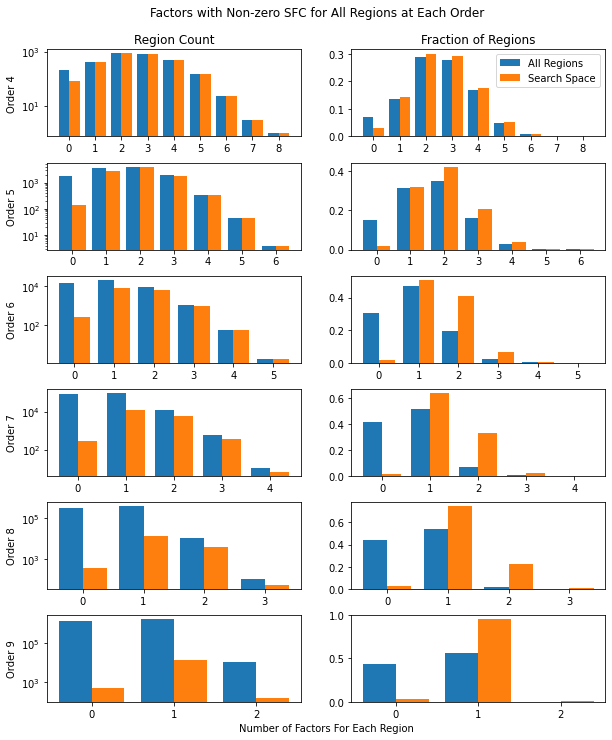

In [6]:
fig, axes = plt.subplots(nrows=6, ncols=2, figsize=(10, 12))
plt.rcParams['axes.facecolor'] = 'white'
plt.subplots_adjust(wspace=0.2, hspace=0.3)

for order, i in zip(range(4, 10), range(6)):
    ss_file = os.path.join(ss_datadir, 'hilbert_regions_order_{}_CT20230630.dhs.cs.sfc.ranks.limited_search_space_top_1000_no_overlap.npz'.format(order))
    full_file = os.path.join(full_datadir, 'hilbert_regions_order_{}_CT20230630.dhs.cs.sfc.ranks.txt'.format(order))
    
    ss = np.load(ss_file)['ranks']
    full = np.loadtxt(full_file, dtype=float, delimiter='\t')
    
    full_count = np.count_nonzero(full, axis=1)
    full_bincount = np.bincount(full_count)
    full_bincount_fract = full_bincount / np.sum(full_bincount)
    
    ss_count = np.count_nonzero(ss, axis=1)
    ss_bincount = np.bincount(ss_count)
    ss_bincount_fract = ss_bincount / np.sum(ss_bincount)
    
    axes[i, 0].bar(np.arange(len(full_bincount)) - 0.2, full_bincount, width=0.4)
    axes[i, 0].bar(np.arange(len(ss_bincount)) + 0.2, ss_bincount, width=0.4)
    axes[i, 0].set_xticks(np.arange(len(full_bincount)))
    axes[i, 0].set_yscale('log')
    axes[i, 0].set_ylabel('Order %s' %order)
    
    axes[i, 1].bar(np.arange(len(full_bincount_fract)) - 0.2, full_bincount_fract, width=0.4)
    axes[i, 1].bar(np.arange(len(ss_bincount_fract)) + 0.2, ss_bincount_fract, width=0.4)
    axes[i, 1].set_xticks(np.arange(len(full_bincount_fract)))
    
axes[0, 0].set_title('Region Count')
axes[0, 1].set_title('Fraction of Regions')
axes[0, 1].legend(['All Regions', 'Search Space'])
axes[-1, 0].set_xlabel('Number of Factors For Each Region', x=1.1)
plt.suptitle('Factors with Non-zero SFC for All Regions at Each Order', y=0.93)

**Finding factors that are significant together**

In [8]:
joint_factor_counts = np.zeros((6, 34, 34), dtype=int)
joint_factor_counts_gt0 = np.zeros((6, 34, 34))
ave_counts_for_2regions = np.zeros((6, 34, 34))

num_regions = np.zeros(6, dtype=int)
for order, i in zip(range(4, 10), range(6)):
    print(order)
#     ss_file = os.path.join(ss_datadir, 'hilbert_regions_order_{}_CT20230630.dhs.cs.sfc.ranks.limited_search_space_top_1000_no_overlap.npz'.format(order))
    full_file = os.path.join(full_datadir, 'hilbert_regions_order_{}_CT20230630.dhs.cs.sfc.ranks.txt'.format(order))
    
#     ss = np.load(ss_file)['ranks']
    full = np.loadtxt(full_file, dtype=float, delimiter='\t')
    arr = full
    
    # number of regions
    num_regions[i] = len(arr)
    
    # count the occurences of all factors for each region
    count_per_region = np.count_nonzero(arr, axis=1)
    
    # count the co-occurences of factors at each order
    for f1 in range(34):
        for f2 in range(34):
            # factors in question
            arr_sub = arr[:, [f1, f2]]
            # regions where both factors significant
            where2 = np.where(np.count_nonzero(arr_sub, axis=1) == 2)[0]
            # number of regions
            count = len(where2)
            # number of regions where either factor is significant
            count_gt0 = len(np.where(np.count_nonzero(arr_sub, axis=1) > 0)[0])
            
            # average number of factors significant when both factors are significant
            if len(where2) > 0:
                counts_for_2regions = count_per_region[where2]
                ave_for_2regions = np.mean(counts_for_2regions)
            else:
                ave_for_2regions = 0
            ave_counts_for_2regions[i, f1, f2] = ave_for_2regions
            
            if f1 == f2:
                count = 0
            joint_factor_counts[i, f1, f2] = count
            joint_factor_counts_gt0[i, f1, f2] = count_gt0
            
joint_factor_counts_gt0 = np.where(joint_factor_counts_gt0 == 0, 0.1, joint_factor_counts_gt0)

4
5
6
7
8
9


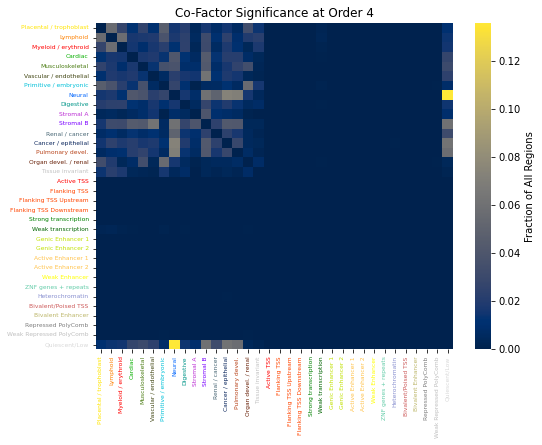

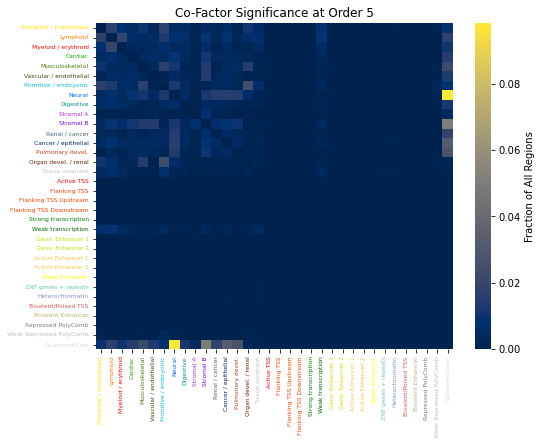

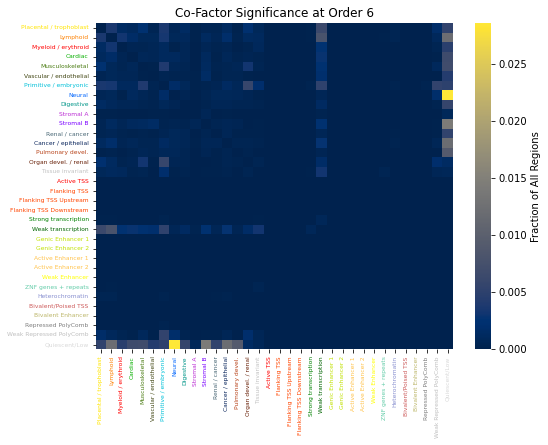

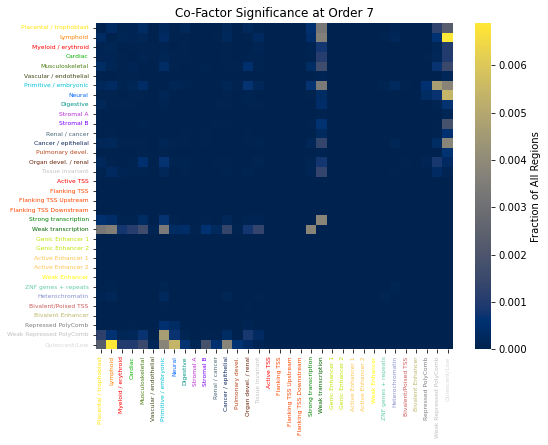

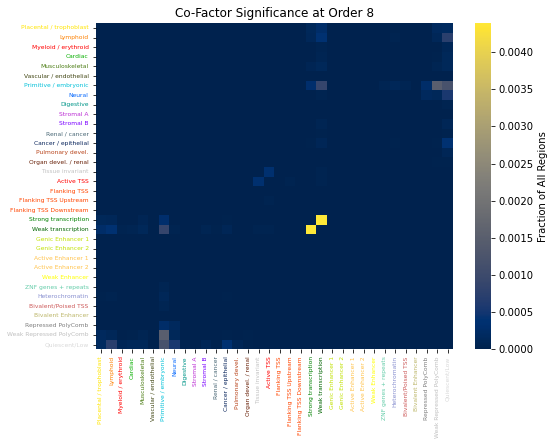

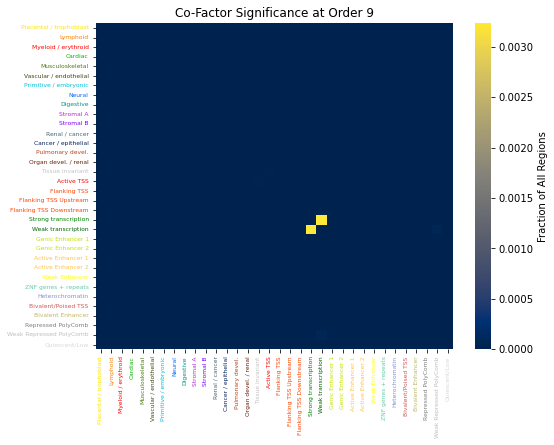

In [9]:
for order, i in zip(range(4, 10), range(6)):
    fig, axes = plt.subplots(figsize=(8, 6))
    plt.rcParams['axes.facecolor'] = 'white'
    
    sns.heatmap(joint_factor_counts[i] / num_regions[i], cmap='cividis', cbar_kws={'label': 'Fraction of All Regions'})
    
    axes.set_yticks(np.arange(34) + 0.5)
    axes.set_xticks(np.arange(34) + 0.5)
    axes.set_yticklabels(factors, rotation=0, size=6)
    axes.set_xticklabels(factors, rotation=90, size=6)
    for labelx, labely, j in zip(axes.xaxis.get_ticklabels(), axes.yaxis.get_ticklabels(), range(40)):
        labelx.set_color(colors[j])
        labely.set_color(colors[j])
    
    axes.set_title('Co-Factor Significance at Order %s' %order)
    plt.show()

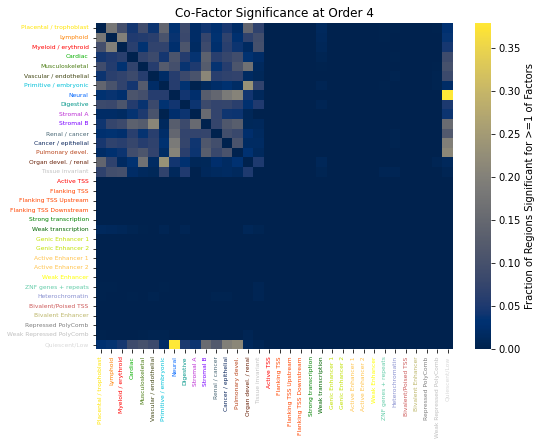

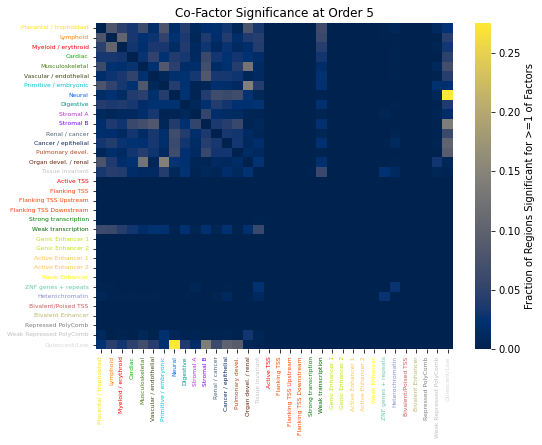

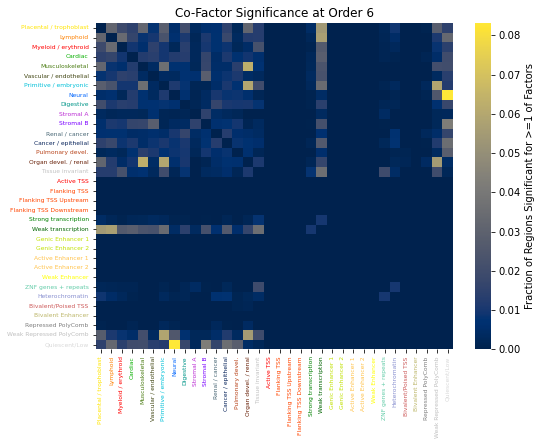

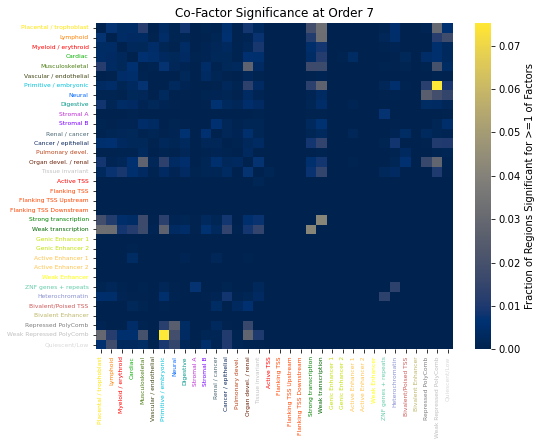

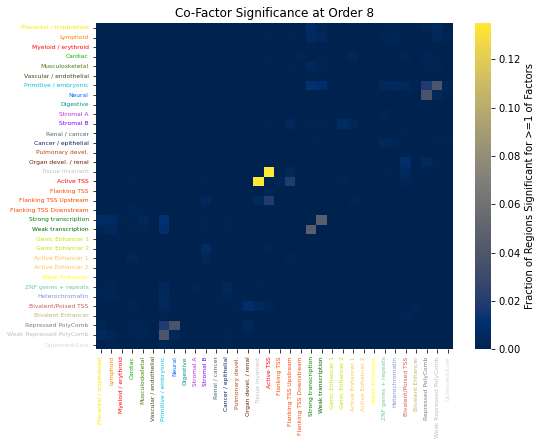

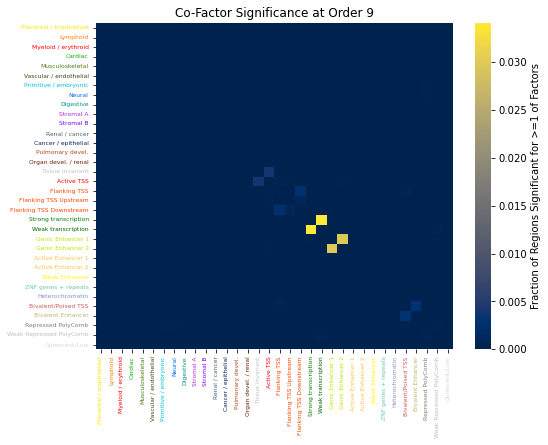

In [10]:
for order, i in zip(range(4, 10), range(6)):
    fig, axes = plt.subplots(figsize=(8, 6))
    plt.rcParams['axes.facecolor'] = 'white'
    
    sns.heatmap(joint_factor_counts[i] / joint_factor_counts_gt0[i], cmap='cividis', cbar_kws={'label': 'Fraction of Regions Significant for >=1 of Factors'})
    
    axes.set_yticks(np.arange(34) + 0.5)
    axes.set_xticks(np.arange(34) + 0.5)
    axes.set_yticklabels(factors, rotation=0, size=6)
    axes.set_xticklabels(factors, rotation=90, size=6)
    for labelx, labely, j in zip(axes.xaxis.get_ticklabels(), axes.yaxis.get_ticklabels(), range(40)):
        labelx.set_color(colors[j])
        labely.set_color(colors[j])
    
    axes.set_title('Co-Factor Significance at Order %s' %order)
    plt.show()

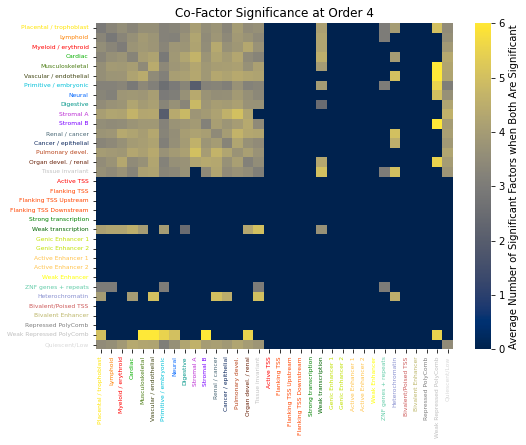

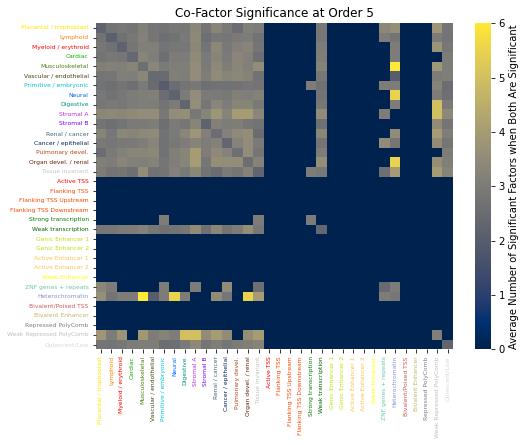

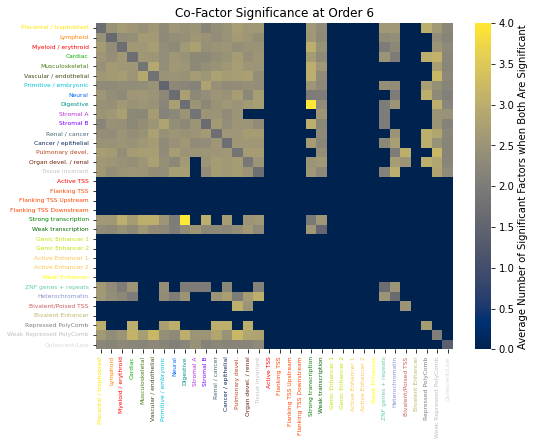

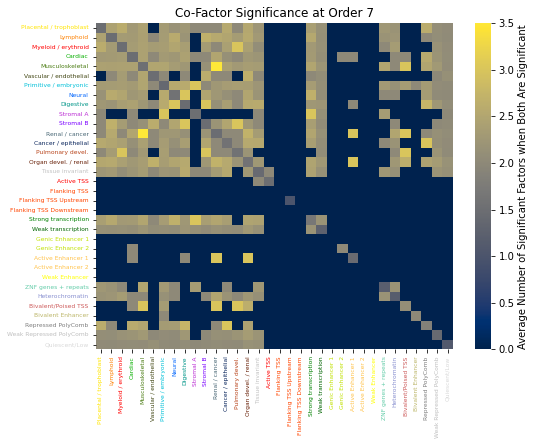

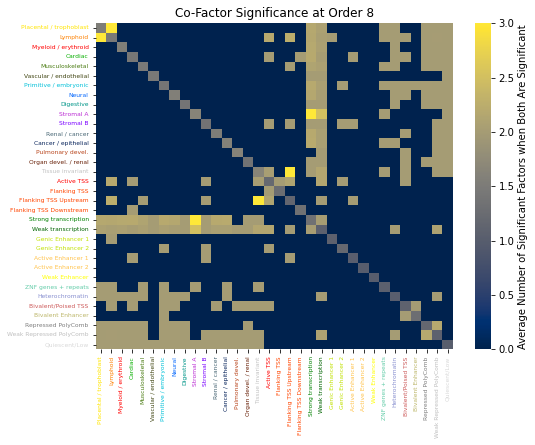

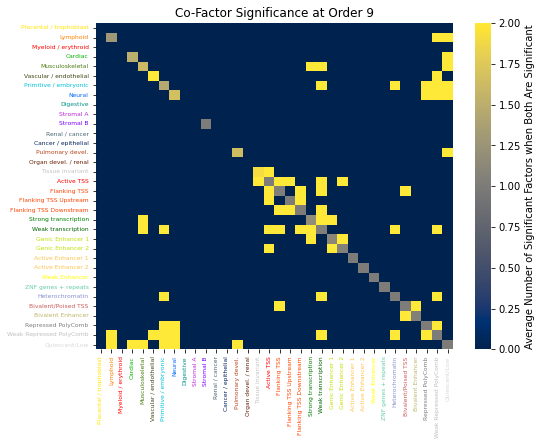

In [11]:
for order, i in zip(range(4, 10), range(6)):
    fig, axes = plt.subplots(figsize=(8, 6))
    plt.rcParams['axes.facecolor'] = 'white'
    
    sns.heatmap(ave_counts_for_2regions[i], cmap='cividis', cbar_kws={'label': 'Average Number of Significant Factors when Both Are Significant'})
    
    axes.set_yticks(np.arange(34) + 0.5)
    axes.set_xticks(np.arange(34) + 0.5)
    axes.set_yticklabels(factors, rotation=0, size=6)
    axes.set_xticklabels(factors, rotation=90, size=6)
    for labelx, labely, j in zip(axes.xaxis.get_ticklabels(), axes.yaxis.get_ticklabels(), range(40)):
        labelx.set_color(colors[j])
        labely.set_color(colors[j])
    
    axes.set_title('Co-Factor Significance at Order %s' %order)
    plt.show()

**Find the top regions for each factor at each order**

In [ ]:
top_regions = {}
for order in range(4, 10):
    print(order)
    
    full_file = os.path.join(full_datadir, 'hilbert_regions_order_{}_CT20230630.dhs.cs.sfc.ranks.hdf5'.format(order))
    f = h5py.File(full_file, 'r')
    coords = np.char.decode(f['coordinates'][:])
    ranks = f['ranks'][:]
    f.close()
    
    order_regions = {}
    for factor in range(34):
        c = coords[np.argmax(ranks[:, factor])]
        order_regions[factor] = c[0] + ':' + c[1] + '-' + c[2]
    top_regions[order] = order_regions

In [ ]:
path = '/Users/ctrader/Documents/AG/NarrativeGenomics/region_narration/region_narration_app/region-narration-app/src/hilbert_orders_4t9.sfc.top_regions_per_factor.json'
with open(path, 'w') as f:
    json.dump(top_regions, f)